In [2]:
from pynq import Overlay
%run can_mcp.py
ol = Overlay("footdrop.bit")
spi = AxiSpi(ol.axi_quad_spi_0.mmio)
#can = Mcp25625(spi, rst_gpio=(ol.gpio_can.mmio, 0x00, 0))
#print(can.init(loopback=True))          # True = SPI is talking to the MCP25625
#can.send(0x123, [1, 2, 3]); print(can.recv())   # expect (291, [1, 2, 3])

In [ ]:
# single raw read: addr 0x68, reg 0x00 -> 1 byte
mmio.write(SOFTR, 0x0A); time.sleep(0.01)
mmio.write(CR, 0x02)                   # TX FIFO reset
mmio.write(CR, 0x01)                   # enable
mmio.write(ISR, 0xFF)                  # clear all interrupt flags (write-1-to-clear)
print("before:", hex(mmio.read(SR)), hex(mmio.read(ISR)))

mmio.write(TX_FIFO, 0x100 | (0x68 << 1))        # START + addr W
mmio.write(TX_FIFO, 0x00)                       # reg 0x00
mmio.write(TX_FIFO, 0x100 | (0x68 << 1) | 1)    # repeated START + addr R
mmio.write(TX_FIFO, 0x200 | 1)                  # STOP + read 1 byte
time.sleep(0.01)
sr, isr = mmio.read(SR), mmio.read(ISR)
print("after :", hex(sr), hex(isr), "RX empty" if sr & 0x40 else f"RX: {hex(mmio.read(RX_FIFO) & 0xFF)}")

In [3]:
from pynq import Overlay
ol = Overlay("footdrop.bit")
mmio = ol.axi_iic_0.mmio
print(hex(ol.axi_iic_0.mmio.base_addr))
mmio.write(SOFTR, 0x0A); time.sleep(0.01)
mmio.write(ISR, 0xFF)
print(hex(mmio.read(ISR)))        # must NOT be 0xff now

0x40800000


NameError: name 'SOFTR' is not defined

In [7]:
mmio.write(SOFTR, 0x0A); time.sleep(0.01)
mmio.write(0x11C, 0x0F)                 # RX_FIFO_PIRQ: accept up to 16 bytes
mmio.write(CR, 0x02)                    # TX FIFO reset
mmio.write(CR, 0x01)                    # enable, master
mmio.write(ISR, mmio.read(ISR))         # toggle-clear whatever is set
print("before:", hex(mmio.read(SR)), hex(mmio.read(ISR)))

A = 0x48
mmio.write(TX_FIFO, 0x100 | (A << 1))         # START, addr+W
mmio.write(TX_FIFO, 0x00)                     # reg 0x00
mmio.write(TX_FIFO, 0x100 | (A << 1) | 1)     # rSTART, addr+R
mmio.write(TX_FIFO, 0x200 | 1)                # STOP after 1 byte
time.sleep(0.01)
sr, isr = mmio.read(SR), mmio.read(ISR)
print("after :", hex(sr), hex(isr), "NACK" if isr & 0x02 else "",
      "RX empty" if sr & 0x40 else f"RX: {hex(mmio.read(RX_FIFO) & 0xFF)}")

before: 0xc0 0xd0
after : 0x40 0xd6 NACK RX empty


In [11]:
print([k for k in ol.ip_dict])

['inference_stream_0', 'gpio_stim', 'gpio_can', 'axi_iic_0', 'xadc_wiz_0', 'axi_quad_spi_0', 'ps7']


In [4]:
import time
for _ in range(50):
    for a in range(0x08, 0x78):
        try: read_regs(a, 0x00, 1)
        except TimeoutError: pass

In [8]:
# single raw read: addr 0x68, reg 0x00 -> 1 byte
mmio.write(SOFTR, 0x0A); time.sleep(0.01)
mmio.write(CR, 0x02)                   # TX FIFO reset
mmio.write(CR, 0x01)                   # enable
mmio.write(ISR, 0xFF)                  # clear all interrupt flags (write-1-to-clear)
print("before:", hex(mmio.read(SR)), hex(mmio.read(ISR)))

mmio.write(TX_FIFO, 0x100 | (0x68 << 1))        # START + addr W
mmio.write(TX_FIFO, 0x00)                       # reg 0x00
mmio.write(TX_FIFO, 0x100 | (0x68 << 1) | 1)    # repeated START + addr R
mmio.write(TX_FIFO, 0x200 | 1)                  # STOP + read 1 byte
time.sleep(0.01)
sr, isr = mmio.read(SR), mmio.read(ISR)
print("after :", hex(sr), hex(isr), "RX empty" if sr & 0x40 else f"RX: {hex(mmio.read(RX_FIFO) & 0xFF)}")

before: 0xc0 0xff
after : 0x40 0xff RX empty


In [14]:
found = []
for a in range(0x08, 0x78):
    try:
        read_regs(a, 0x00, 1); found.append(hex(a))
    except TimeoutError:
        pass
print(found)

['0x48', '0x68']


In [12]:
import time
mmio = ol.axi_iic_0.mmio
SOFTR, CR, SR, TX_FIFO, RX_FIFO, ISR = 0x040, 0x100, 0x104, 0x108, 0x10C, 0x020
START, STOP = 0x100, 0x200
BMI160 = 0x68

def iic_reset():
    mmio.write(SOFTR, 0x0A); time.sleep(0.01)
    mmio.write(CR, 0x01);    time.sleep(0.001)

iic_reset()
print(hex(mmio.read(SR)))
print("I2C ready")

0xc0
I2C ready


In [13]:
def write_reg(device, reg, value):
    mmio.write(TX_FIFO, START | (device << 1))
    mmio.write(TX_FIFO, reg)
    mmio.write(TX_FIFO, STOP | value)
    time.sleep(0.002)

def _read_regs_once(device_addr, start_reg, count):
    mmio.write(TX_FIFO, START | (device_addr << 1))
    mmio.write(TX_FIFO, start_reg)
    mmio.write(TX_FIFO, START | (device_addr << 1) | 1)
    mmio.write(TX_FIFO, STOP | count)
    data, deadline = [], time.perf_counter() + 0.02
    while len(data) < count:
        if (mmio.read(SR) & 0x40) == 0:
            data.append(mmio.read(RX_FIFO) & 0xFF)
        if time.perf_counter() > deadline:
            raise TimeoutError(f"I2C timeout {len(data)}/{count}")
    return data

def read_regs(device_addr, start_reg, count):
    try:
        return _read_regs_once(device_addr, start_reg, count)
    except TimeoutError:
        iic_reset()
        return _read_regs_once(device_addr, start_reg, count)

In [5]:
iic_reset()
write_reg(BMI160, 0x7E, 0xB6); time.sleep(0.15)  # soft reset
write_reg(BMI160, 0x7E, 0x11); time.sleep(0.10)  # accel normal mode
write_reg(BMI160, 0x7E, 0x15); time.sleep(0.10)  # gyro normal mode
write_reg(BMI160, 0x40, 0x28)                     # accel 100 Hz
write_reg(BMI160, 0x41, 0x03)                     # ±2 g
write_reg(BMI160, 0x42, 0x28)                     # gyro 100 Hz
write_reg(BMI160, 0x43, 0x03)                     # ±250 dps
print("CHIP_ID:", hex(read_regs(BMI160, 0x00, 1)[0]), "(expect 0xd1)")

TimeoutError: I2C timeout 0/1

In [6]:
def signed16(lo, hi):
    v = (hi << 8) | lo
    return v - 65536 if v >= 32768 else v

def read_imu():
    d = read_regs(BMI160, 0x0C, 12)
    gx, gy, gz = signed16(d[0],d[1]), signed16(d[2],d[3]), signed16(d[4],d[5])
    ax, ay, az = signed16(d[6],d[7]), signed16(d[8],d[9]), signed16(d[10],d[11])
    return ax/16384.0, ay/16384.0, az/16384.0, gx/131.2, gy/131.2, gz/131.2

In [7]:
ADS1015 = 0x48

def iic_write_bytes(device_addr, data):
    mmio.write(TX_FIFO, START | (device_addr << 1))
    for b in data[:-1]:
        mmio.write(TX_FIFO, b)
    mmio.write(TX_FIFO, STOP | data[-1])
    time.sleep(0.002)

def iic_write_then_read(device_addr, write_data, read_count):
    mmio.write(TX_FIFO, START | (device_addr << 1))
    for b in write_data:
        mmio.write(TX_FIFO, b)
    mmio.write(TX_FIFO, START | (device_addr << 1) | 1)
    mmio.write(TX_FIFO, STOP | read_count)
    data, deadline = [], time.perf_counter() + 0.05
    while len(data) < read_count:
        if (mmio.read(SR) & 0x40) == 0:
            data.append(mmio.read(RX_FIFO) & 0xFF)
        if time.perf_counter() > deadline:
            raise TimeoutError(f"ADS1015 timeout {len(data)}/{read_count}")
    return data

def init_ads1015():
    config = 0xC283
    iic_write_bytes(ADS1015, [0x01, (config >> 8) & 0xFF, config & 0xFF])
    time.sleep(0.010)

def read_emg_raw():
    b = iic_write_then_read(ADS1015, [0x00], 2)
    raw = ((b[0] << 8) | b[1]) >> 4
    if raw >= 2048: raw -= 4096
    return raw, raw * 0.002

init_ads1015()
print("ADS1015 ready")

ADS1015 ready


In [8]:
xadc_mmio = ol.xadc_wiz_0.mmio
FSR_HEEL, FSR_TOE = 0x244, 0x264   # A0/VAUX1, A1/VAUX9

def read_xadc(offset):
    raw = (xadc_mmio.read(offset) >> 4) & 0xFFF
    return raw, raw * 3.3 / 4095.0

def read_fsrs():
    _, heel = read_xadc(FSR_HEEL)
    _, toe  = read_xadc(FSR_TOE)
    return heel, toe

In [21]:
%run pynq_data_logger.py
import pynq_data_logger as logger
logger.read_emg_raw = read_emg_raw
logger.read_regs    = read_regs
logger.write_reg    = write_reg
subject_id = "subject01"
for n in ["read_regs","read_emg_raw","write_reg"]:
    print(n, "OK" if hasattr(logger, n) else "MISSING")
logger.verify_bmi160_scale()

read_regs OK
read_emg_raw OK
write_reg OK


TimeoutError: I2C timeout 0/1

In [10]:
print("EMG — lift toes toward shin:")
for _ in range(40): print(logger.read_emg_raw()); time.sleep(0.05)

EMG — lift toes toward shin:
(971, 1.942)
(971, 1.942)
(969, 1.938)
(969, 1.938)
(970, 1.94)
(970, 1.94)
(969, 1.938)
(967, 1.934)
(969, 1.938)
(970, 1.94)
(969, 1.938)
(970, 1.94)
(969, 1.938)
(969, 1.938)
(970, 1.94)
(974, 1.948)
(969, 1.938)
(970, 1.94)
(970, 1.94)
(969, 1.938)
(970, 1.94)
(970, 1.94)
(970, 1.94)
(970, 1.94)
(971, 1.942)
(970, 1.94)
(969, 1.938)
(970, 1.94)
(970, 1.94)
(969, 1.938)
(968, 1.936)
(969, 1.938)
(969, 1.938)
(970, 1.94)
(970, 1.94)
(970, 1.94)
(970, 1.94)
(970, 1.94)
(970, 1.94)
(968, 1.936)


In [11]:
print("FSR — press heel, then toe:")
for _ in range(40): print(read_fsrs()); time.sleep(0.05)

FSR — press heel, then toe:
(3.236336996336996, 3.187179487179487)
(3.236336996336996, 3.187179487179487)
(3.237948717948718, 3.1928205128205125)
(3.2403663003663, 3.187985347985348)
(3.2403663003663, 3.1887912087912085)
(3.2403663003663, 3.192014652014652)
(3.2548717948717947, 3.1912087912087914)
(3.2339194139194136, 3.1976556776556775)
(3.244395604395604, 3.194432234432234)
(3.2395604395604396, 3.1895970695970695)
(3.2347252747252746, 3.187179487179487)
(3.2347252747252746, 3.19040293040293)
(3.2516483516483516, 3.1887912087912085)
(3.236336996336996, 3.1887912087912085)
(3.2371428571428567, 3.182344322344322)
(3.2387545787545786, 3.19040293040293)
(3.2395604395604396, 3.187179487179487)
(3.2403663003663, 3.19040293040293)
(3.236336996336996, 3.187985347985348)
(3.237948717948718, 3.186373626373626)
(3.2298901098901096, 3.187179487179487)
(3.232307692307692, 3.17992673992674)
(3.236336996336996, 3.187985347985348)
(3.2371428571428567, 3.187985347985348)
(3.236336996336996, 3.19040293

In [12]:
print("IMU — rotate the foot:")
for _ in range(40): print(logger.read_imu_frame()); time.sleep(0.05)

IMU — rotate the foot:
(-0.2420654296875, -0.0545654296875, 0.95855712890625, 0.40396341463414637, -0.06859756097560976, -1.3185975609756098)
(-0.24359130859375, -0.05413818359375, 0.95849609375, 0.7698170731707318, -0.5487804878048781, -3.1250000000000004)
(-0.24188232421875, -0.05413818359375, 0.9586181640625, 0.8841463414634148, -0.9298780487804879, -3.19359756097561)
(-0.2418212890625, -0.05133056640625, 0.95709228515625, 1.1051829268292683, -1.211890243902439, -3.3841463414634148)
(-0.23419189453125, -0.0526123046875, 0.95745849609375, 1.1890243902439026, -1.3414634146341464, -4.275914634146342)
(-0.23455810546875, -0.04949951171875, 0.9578857421875, 0.8689024390243903, -1.3719512195121952, -3.894817073170732)
(-0.2353515625, -0.05181884765625, 0.9600830078125, 0.9756097560975611, -1.3414634146341464, -4.923780487804878)
(-0.23114013671875, -0.05157470703125, 0.9578857421875, 0.4573170731707317, -1.1128048780487805, -3.5289634146341466)
(-0.22772216796875, -0.05072021484375, 0.959

In [16]:
logger.record_standing_baseline(read_fsrs, duration_s=30, subject_id=subject_id)

Starting 30 s 'standing_still' trial in 3 seconds...
RECORDING
DONE
EMG samples: 26755 (891.9 Hz)
FSR samples: 3000
IMU frames:   3000 (100.0 Hz)
Saved: ankle_dataset/subject01_standing_still_20250504T104120Z_emg.csv, ankle_dataset/subject01_standing_still_20250504T104120Z_fsr.csv, ankle_dataset/subject01_standing_still_20250504T104120Z_imu.csv, ankle_dataset/subject01_standing_still_20250504T104120Z_meta.json


(PosixPath('ankle_dataset/subject01_standing_still_20250504T104120Z_emg.csv'),
 PosixPath('ankle_dataset/subject01_standing_still_20250504T104120Z_fsr.csv'),
 PosixPath('ankle_dataset/subject01_standing_still_20250504T104120Z_imu.csv'),
 PosixPath('ankle_dataset/subject01_standing_still_20250504T104120Z_meta.json'))

In [15]:
logger.record_trial("walk1", 60, read_fsrs, subject_id=subject_id)

Starting 60 s 'walk1' trial in 3 seconds...
RECORDING
DONE
EMG samples: 53772 (896.2 Hz)
FSR samples: 5998
IMU frames:   5998 (100.0 Hz)
Saved: ankle_dataset/subject01_walk1_20250504T103642Z_emg.csv, ankle_dataset/subject01_walk1_20250504T103642Z_fsr.csv, ankle_dataset/subject01_walk1_20250504T103642Z_imu.csv, ankle_dataset/subject01_walk1_20250504T103642Z_meta.json


(PosixPath('ankle_dataset/subject01_walk1_20250504T103642Z_emg.csv'),
 PosixPath('ankle_dataset/subject01_walk1_20250504T103642Z_fsr.csv'),
 PosixPath('ankle_dataset/subject01_walk1_20250504T103642Z_imu.csv'),
 PosixPath('ankle_dataset/subject01_walk1_20250504T103642Z_meta.json'))

Trial: subject01_walk8_20250504T111035Z 

EMG   n=53790  rate=  896.6 Hz  max_gap=  8.91 ms  gaps>5ms: 8
FSR   n= 6000  rate=  100.0 Hz  max_gap= 12.91 ms  gaps>5ms: 5999
IMU   n= 6000  rate=  100.0 Hz  max_gap= 12.91 ms  gaps>5ms: 5999

Start stomps detected: 5  at [0.44, 1.03, 2.82, 4.72, 6.89]
End   stomps detected: 3  at [53.59, 56.14, 58.85]


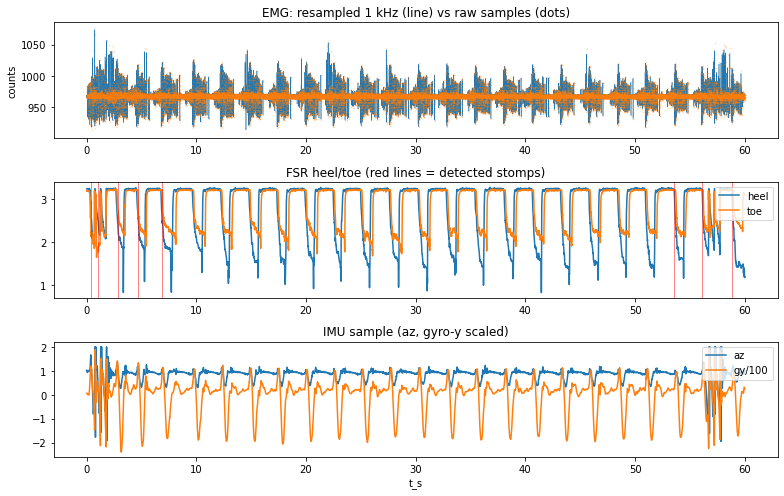

In [34]:
import numpy as np, pandas as pd, glob, os
import matplotlib.pyplot as plt

def validate_trial(prefix=None, output_dir="ankle_dataset"):
    # --- find the trial ---
    if prefix is None:
        metas = sorted(glob.glob(os.path.join(output_dir, "*_meta.json")),
                       key=os.path.getmtime)
        if not metas:
            print("No trials found in", output_dir); return
        prefix = metas[-1][:-len("_meta.json")]
    emg = pd.read_csv(prefix + "_emg.csv")
    fsr = pd.read_csv(prefix + "_fsr.csv")
    imu = pd.read_csv(prefix + "_imu.csv")
    print("Trial:", os.path.basename(prefix), "\n")

    # --- per-stream real rate + worst gap ---
    for name, df in [("EMG", emg), ("FSR", fsr), ("IMU", imu)]:
        t = df["t_s"].to_numpy()
        gaps = np.diff(t)
        dur = t[-1] - t[0]
        print(f"{name:4s}  n={len(t):5d}  rate={len(t)/dur:7.1f} Hz  "
              f"max_gap={gaps.max()*1000:6.2f} ms  "
              f"gaps>5ms: {(gaps>0.005).sum()}")
    print()

    # --- resample EMG onto the exact 1000 Hz training grid ---
    t_grid = np.arange(emg.t_s.iloc[0], emg.t_s.iloc[-1], 1/1000)
    emg_1k = np.interp(t_grid, emg.t_s, emg.emg_counts)

    # --- find stomps: sharp heel-FSR spikes in first/last 8 s ---
    def stomps(df, col, t_lo, t_hi):
        w = df[(df.t_s >= t_lo) & (df.t_s <= t_hi)]
        x = w[col].to_numpy(); t = w.t_s.to_numpy()
        d = np.abs(x - np.median(x))
        thr = 4 * (np.median(d) + 1e-9)
        hits = t[d > thr]
        # cluster times within 0.25 s into one event
        ev = [h for i, h in enumerate(hits) if i == 0 or h - hits[i-1] > 0.25]
        return ev
    start_ev = stomps(fsr, "fsr_heel", fsr.t_s.iloc[0], fsr.t_s.iloc[0] + 8)
    end_ev   = stomps(fsr, "fsr_heel", fsr.t_s.iloc[-1] - 8, fsr.t_s.iloc[-1])
    print(f"Start stomps detected: {len(start_ev)}  at "
          f"{[round(e,2) for e in start_ev]}")
    print(f"End   stomps detected: {len(end_ev)}  at "
          f"{[round(e,2) for e in end_ev]}")

    # --- plots ---
    fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=False)
    ax[0].plot(t_grid, emg_1k, lw=0.5)
    ax[0].plot(emg.t_s, emg.emg_counts, ".", ms=1, alpha=0.3)
    ax[0].set_title("EMG: resampled 1 kHz (line) vs raw samples (dots)")
    ax[0].set_ylabel("counts")

    ax[1].plot(fsr.t_s, fsr.fsr_heel, label="heel")
    ax[1].plot(fsr.t_s, fsr.fsr_toe, label="toe")
    for e in start_ev + end_ev:
        ax[1].axvline(e, color="r", lw=0.8, alpha=0.6)
    ax[1].set_title("FSR heel/toe (red lines = detected stomps)")
    ax[1].legend(loc="upper right")

    ax[2].plot(imu.t_s, imu.az_g, label="az")
    ax[2].plot(imu.t_s, imu.gy_dps/100, label="gy/100")
    ax[2].set_title("IMU sample (az, gyro-y scaled)")
    ax[2].set_xlabel("t_s"); ax[2].legend(loc="upper right")
    plt.tight_layout(); plt.show()

validate_trial()   # or validate_trial(prefix="ankle_dataset/subject01_walk_level_2026...")


In [19]:
logger.record_trial("walk2", 60, read_fsrs, subject_id=subject_id)

Starting 60 s 'walk2' trial in 3 seconds...
RECORDING
DONE
EMG samples: 53686 (894.8 Hz)
FSR samples: 5998
IMU frames:   5998 (100.0 Hz)
Saved: ankle_dataset/subject01_walk2_20250504T104729Z_emg.csv, ankle_dataset/subject01_walk2_20250504T104729Z_fsr.csv, ankle_dataset/subject01_walk2_20250504T104729Z_imu.csv, ankle_dataset/subject01_walk2_20250504T104729Z_meta.json


(PosixPath('ankle_dataset/subject01_walk2_20250504T104729Z_emg.csv'),
 PosixPath('ankle_dataset/subject01_walk2_20250504T104729Z_fsr.csv'),
 PosixPath('ankle_dataset/subject01_walk2_20250504T104729Z_imu.csv'),
 PosixPath('ankle_dataset/subject01_walk2_20250504T104729Z_meta.json'))

In [21]:
logger.record_trial("walk3", 60, read_fsrs, subject_id=subject_id)

Starting 60 s 'walk3' trial in 3 seconds...
RECORDING
DONE
EMG samples: 53733 (895.6 Hz)
FSR samples: 6000
IMU frames:   6000 (100.0 Hz)
Saved: ankle_dataset/subject01_walk3_20250504T105059Z_emg.csv, ankle_dataset/subject01_walk3_20250504T105059Z_fsr.csv, ankle_dataset/subject01_walk3_20250504T105059Z_imu.csv, ankle_dataset/subject01_walk3_20250504T105059Z_meta.json


(PosixPath('ankle_dataset/subject01_walk3_20250504T105059Z_emg.csv'),
 PosixPath('ankle_dataset/subject01_walk3_20250504T105059Z_fsr.csv'),
 PosixPath('ankle_dataset/subject01_walk3_20250504T105059Z_imu.csv'),
 PosixPath('ankle_dataset/subject01_walk3_20250504T105059Z_meta.json'))

In [23]:
logger.record_trial("walk4", 60, read_fsrs, subject_id=subject_id)

Starting 60 s 'walk4' trial in 3 seconds...
RECORDING
DONE
EMG samples: 53670 (894.5 Hz)
FSR samples: 5998
IMU frames:   5998 (100.0 Hz)
Saved: ankle_dataset/subject01_walk4_20250504T105422Z_emg.csv, ankle_dataset/subject01_walk4_20250504T105422Z_fsr.csv, ankle_dataset/subject01_walk4_20250504T105422Z_imu.csv, ankle_dataset/subject01_walk4_20250504T105422Z_meta.json


(PosixPath('ankle_dataset/subject01_walk4_20250504T105422Z_emg.csv'),
 PosixPath('ankle_dataset/subject01_walk4_20250504T105422Z_fsr.csv'),
 PosixPath('ankle_dataset/subject01_walk4_20250504T105422Z_imu.csv'),
 PosixPath('ankle_dataset/subject01_walk4_20250504T105422Z_meta.json'))

In [27]:
logger.record_trial("walk5", 60, read_fsrs, subject_id=subject_id)

Starting 60 s 'walk5' trial in 3 seconds...
RECORDING
DONE
EMG samples: 53787 (896.5 Hz)
FSR samples: 6000
IMU frames:   6000 (100.0 Hz)
Saved: ankle_dataset/subject01_walk5_20250504T110055Z_emg.csv, ankle_dataset/subject01_walk5_20250504T110055Z_fsr.csv, ankle_dataset/subject01_walk5_20250504T110055Z_imu.csv, ankle_dataset/subject01_walk5_20250504T110055Z_meta.json


(PosixPath('ankle_dataset/subject01_walk5_20250504T110055Z_emg.csv'),
 PosixPath('ankle_dataset/subject01_walk5_20250504T110055Z_fsr.csv'),
 PosixPath('ankle_dataset/subject01_walk5_20250504T110055Z_imu.csv'),
 PosixPath('ankle_dataset/subject01_walk5_20250504T110055Z_meta.json'))

In [29]:
logger.record_trial("walk6", 60, read_fsrs, subject_id=subject_id)

Starting 60 s 'walk6' trial in 3 seconds...
RECORDING
DONE
EMG samples: 53715 (895.3 Hz)
FSR samples: 6000
IMU frames:   6000 (100.0 Hz)
Saved: ankle_dataset/subject01_walk6_20250504T110356Z_emg.csv, ankle_dataset/subject01_walk6_20250504T110356Z_fsr.csv, ankle_dataset/subject01_walk6_20250504T110356Z_imu.csv, ankle_dataset/subject01_walk6_20250504T110356Z_meta.json


(PosixPath('ankle_dataset/subject01_walk6_20250504T110356Z_emg.csv'),
 PosixPath('ankle_dataset/subject01_walk6_20250504T110356Z_fsr.csv'),
 PosixPath('ankle_dataset/subject01_walk6_20250504T110356Z_imu.csv'),
 PosixPath('ankle_dataset/subject01_walk6_20250504T110356Z_meta.json'))

In [31]:
logger.record_trial("walk7", 60, read_fsrs, subject_id=subject_id)

Starting 60 s 'walk7' trial in 3 seconds...
RECORDING
DONE
EMG samples: 53786 (896.5 Hz)
FSR samples: 6000
IMU frames:   6000 (100.0 Hz)
Saved: ankle_dataset/subject01_walk7_20250504T110744Z_emg.csv, ankle_dataset/subject01_walk7_20250504T110744Z_fsr.csv, ankle_dataset/subject01_walk7_20250504T110744Z_imu.csv, ankle_dataset/subject01_walk7_20250504T110744Z_meta.json


(PosixPath('ankle_dataset/subject01_walk7_20250504T110744Z_emg.csv'),
 PosixPath('ankle_dataset/subject01_walk7_20250504T110744Z_fsr.csv'),
 PosixPath('ankle_dataset/subject01_walk7_20250504T110744Z_imu.csv'),
 PosixPath('ankle_dataset/subject01_walk7_20250504T110744Z_meta.json'))

In [33]:
logger.record_trial("walk8", 60, read_fsrs, subject_id=subject_id)

Starting 60 s 'walk8' trial in 3 seconds...
RECORDING
DONE
EMG samples: 53790 (896.5 Hz)
FSR samples: 6000
IMU frames:   6000 (100.0 Hz)
Saved: ankle_dataset/subject01_walk8_20250504T111035Z_emg.csv, ankle_dataset/subject01_walk8_20250504T111035Z_fsr.csv, ankle_dataset/subject01_walk8_20250504T111035Z_imu.csv, ankle_dataset/subject01_walk8_20250504T111035Z_meta.json


(PosixPath('ankle_dataset/subject01_walk8_20250504T111035Z_emg.csv'),
 PosixPath('ankle_dataset/subject01_walk8_20250504T111035Z_fsr.csv'),
 PosixPath('ankle_dataset/subject01_walk8_20250504T111035Z_imu.csv'),
 PosixPath('ankle_dataset/subject01_walk8_20250504T111035Z_meta.json'))